# PII: detecting and hiding private information

**Is PII a guardrail?** Yes. _Sensitive Information Disclosure_ is **#2 on the OWASP LLM Top 10 (2026)**,
and LangChain ships a built-in `PIIMiddleware` for exactly this. Laws like GDPR, India's DPDP Act and
HIPAA make it a legal issue, not only a nice-to-have.

PII (_Personally Identifiable Information_) can leak in **three** places:

1. **In:** the user types it (it then gets logged, stored, sent to a model provider)
2. **Through tools:** a database or web page returns it
3. **Out:** the AI repeats it to someone who shouldn't see it

**In this episode**

- Regex detectors for email, phone, credit card (with a **Luhn** check), Aadhaar, PAN, US SSN, IP address
- Four strategies: **redact**, **mask**, **hash**, **block**
- Run the PII guard on the **input** and the **output** of our graph


## Step 1 — Why the original `"@" in word` check isn't enough

The starter code hid any word containing `@`. Let's test it.


In [1]:
def old_hide_email(message: str) -> str:
    """The original version: hide any word with an @ in it."""
    return " ".join("[EMAIL HIDDEN]" if "@" in w else w for w in message.split())


for msg in [
    "My email is bob@example.com",
    "Ping @yash on Slack",  # a username, not an email
    "Call me on +91 98765 43210",  # phone: missed
    "Card 4111 1111 1111 1111 exp 12/29",  # card: missed
]:
    print(f"{msg!r:42} -> {old_hide_email(msg)!r}")

'My email is bob@example.com'              -> 'My email is [EMAIL HIDDEN]'
'Ping @yash on Slack'                      -> 'Ping [EMAIL HIDDEN] on Slack'
'Call me on +91 98765 43210'               -> 'Call me on +91 98765 43210'
'Card 4111 1111 1111 1111 exp 12/29'       -> 'Card 4111 1111 1111 1111 exp 12/29'


It hides a Slack username (false positive) and misses phones and cards (false negatives).

## Step 2 — Detectors

Each kind of PII gets a regex. Credit cards also get a **Luhn checksum** — every real card number
passes it, so random 16-digit numbers (order IDs) aren't flagged.


In [2]:
import hashlib
import re
from typing import Callable, Literal

Strategy = Literal["redact", "mask", "hash", "block"]

# Order matters: long numbers (cards) are checked before shorter ones (phones).
PII_PATTERNS: dict[str, re.Pattern[str]] = {
    "email": re.compile(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"),
    "credit_card": re.compile(r"\b(?:\d[ -]?){12,18}\d\b"),
    "aadhaar": re.compile(r"(?<!\d)(?<!\d[ -])\d{4}[ -]?\d{4}[ -]?\d{4}(?![ -]?\d)"),  # not part of a longer number
    "us_ssn": re.compile(r"\b\d{3}-\d{2}-\d{4}\b"),
    "pan": re.compile(r"\b[A-Z]{5}\d{4}[A-Z]\b"),
    "ip_address": re.compile(r"\b(?:(?:25[0-5]|2[0-4]\d|1?\d?\d)\.){3}(?:25[0-5]|2[0-4]\d|1?\d?\d)\b"),
    "phone": re.compile(r"(?<![\w+])(?:\+\d{1,3}[ -]?)?(?:\(?\d{3}\)?[ -.]?\d{3}[ -.]?\d{4}|\d{5}[ -]?\d{5})(?!\w)"),
}


def luhn_ok(number: str) -> bool:
    """The Luhn checksum every real card number passes. Stops random digits being called a card."""
    digits = [int(d) for d in number if d.isdigit()]
    total = 0
    for i, d in enumerate(reversed(digits)):
        if i % 2 == 1:
            d = d * 2 - 9 if d > 4 else d * 2
        total += d
    return total % 10 == 0


# Extra checks for patterns that are too greedy on their own.
VALIDATORS: dict[str, Callable[[str], bool]] = {"credit_card": luhn_ok}


def mask_value(kind: str, value: str) -> str:
    """Hide most of the value but keep a hint: b***@example.com, ******3210."""
    if kind == "email":
        name, domain = value.split("@", 1)
        return name[0] + "***@" + domain
    keep = 4
    seen = 0
    out: list[str] = []
    for ch in reversed(value):
        if ch.isalnum():
            out.append(ch if seen < keep else "*")
            seen += 1
        else:
            out.append(ch)
    return "".join(reversed(out))


def hash_value(kind: str, value: str) -> str:
    """Same input -> same token, so we can still match records without seeing the value."""
    return f"<{kind.upper()}:{hashlib.sha256(value.encode()).hexdigest()[:8]}>"

In [3]:
print("4111 1111 1111 1111 ->", luhn_ok("4111 1111 1111 1111"))  # a test Visa number
print("1234 5678 9012 3456 ->", luhn_ok("1234 5678 9012 3456"))  # random digits
print(mask_value("email", "bob@example.com"))
print(mask_value("phone", "+91 98765 43210"))
print(hash_value("pan", "ABCDE1234F"))

4111 1111 1111 1111 -> True
1234 5678 9012 3456 -> False
b***@example.com
+** ***** *3210
<PAN:6442fd73>


## Step 3 — Strategies and policy

| Strategy   | Result             | Use when                                              |
| ---------- | ------------------ | ----------------------------------------------------- |
| **redact** | `[EMAIL]`          | the AI doesn't need it at all                         |
| **mask**   | `******3210`       | a human may need a hint ("card ending 1111")          |
| **hash**   | `<PAN:1a2b3c4d>`   | you need to match records without seeing the value    |
| **block**  | refuse the request | it should never enter the system (card numbers, SSNs) |

These are the same four strategies LangChain's `PIIMiddleware` offers.


In [4]:
# What to do with each kind of private info. This is a business decision, not a coding one.
PII_POLICY: dict[str, Strategy] = {
    "email": "redact",
    "phone": "mask",
    "credit_card": "block",
    "aadhaar": "mask",
    "pan": "hash",
    "us_ssn": "block",
    "ip_address": "hash",
}


def scrub_pii(text: str, policy: dict[str, Strategy] = PII_POLICY) -> tuple[str, list[str], bool]:
    """Find PII and apply the policy.

    Returns (clean_text, kinds_found, must_block).
    """
    found: list[str] = []
    must_block = False

    for kind, pattern in PII_PATTERNS.items():

        def replace(m: re.Match[str], kind: str = kind) -> str:
            nonlocal must_block
            value = m.group(0)
            check = VALIDATORS.get(kind)
            if check and not check(value):
                return value  # looked like PII, but isn't
            found.append(kind)
            strategy = policy.get(kind, "redact")
            if strategy == "block":
                must_block = True
                return f"[{kind.upper()}]"
            if strategy == "mask":
                return mask_value(kind, value)
            if strategy == "hash":
                return hash_value(kind, value)
            return f"[{kind.upper()}]"

        text = pattern.sub(replace, text)

    return text, found, must_block

In [5]:
def print_table(rows: list[tuple[str, ...]], headers: tuple[str, ...]) -> None:
    """Print rows as a neat text table (handy for the video)."""
    widths = [max(len(str(x)) for x in col) for col in zip(headers, *rows)]
    line = " | ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("-" * len(line))
    for row in rows:
        print(" | ".join(str(x).ljust(w) for x, w in zip(row, widths)))

In [6]:
samples: list[str] = [
    "My email is bob@example.com.",
    "Ping @yash on Slack",
    "Call me on +91 98765 43210 or (555) 123-4567",
    "My card is 4111 1111 1111 1111",
    "Order number 1234 5678 9012 3456",
    "Aadhaar 2345 6789 0123, PAN ABCDE1234F",
    "Server 192.168.1.10 is down",
    "SSN 123-45-6789",
]

rows: list[tuple[str, str, str, str]] = []
for s in samples:
    clean, kinds, block = scrub_pii(s)
    rows.append((s, clean, ",".join(kinds) or "-", "BLOCK" if block else ""))

print_table(rows, ("input", "after scrub", "found", ""))

input                                        | after scrub                                  | found       |      
-----------------------------------------------------------------------------------------------------------------
My email is bob@example.com.                 | My email is [EMAIL].                         | email       |      
Ping @yash on Slack                          | Ping @yash on Slack                          | -           |      
Call me on +91 98765 43210 or (555) 123-4567 | Call me on +** ***** *3210 or (***) ***-4567 | phone,phone |      
My card is 4111 1111 1111 1111               | My card is [CREDIT_CARD]                     | credit_card | BLOCK
Order number 1234 5678 9012 3456             | Order number 1234 5678 9012 3456             | -           |      
Aadhaar 2345 6789 0123, PAN ABCDE1234F       | Aadhaar **** **** 0123, PAN <PAN:6442fd73>   | aadhaar,pan |      
Server 192.168.1.10 is down                  | Server <IP_ADDRESS:805ebf20> is down     

Note the order number: it looks like a card, fails Luhn, and is left alone.

> Aadhaar numbers also have a Verhoeff checksum; a production detector would check it the same way we check Luhn.

## Step 4 — Put PII guards on both sides of the AI

To show the **output** side, our pretend helper "remembers" a customer record and repeats it — exactly
how a real model leaks data that sits in its context or a retrieved document.


In [7]:
from typing import Literal, TypedDict, cast

from langgraph.graph import END, START, StateGraph
from langgraph.graph.state import CompiledStateGraph


class Backpack(TypedDict, total=False):
    message: str
    role: str
    answer: str
    blocked: bool
    reason: str
    pii_found: list[str]  # what kinds of PII the guards saw (great for logs/audits)


CUSTOMER_RECORD: str = "Bob Smith, bob@example.com, phone 98765 43210, card 4111 1111 1111 1111"


def guard_input(state: Backpack) -> Backpack:
    """Guard 1 (PII part): clean the message before the AI ever sees it."""
    clean, kinds, block = scrub_pii(state.get("message", ""))
    if block:
        return {
            "blocked": True,
            "reason": "please don't share " + ", ".join(sorted(set(kinds))),
            "pii_found": kinds,
        }
    return {"blocked": False, "message": clean, "pii_found": kinds}


def helper(state: Backpack) -> Backpack:
    """Pretend AI: echoes what it received, or leaks the customer record."""
    if "customer" in state.get("message", "").lower():
        return {"answer": "Here is the customer: " + CUSTOMER_RECORD}
    return {"answer": "You said: " + state.get("message", "")}


def guard_output(state: Backpack) -> Backpack:
    """Guard 3 (PII part): never show raw PII. Mask cards here instead of blocking the answer."""
    out_policy: dict[str, Strategy] = {**PII_POLICY, "credit_card": "mask", "us_ssn": "redact"}
    clean, kinds, _ = scrub_pii(state.get("answer", ""), out_policy)
    return {"answer": clean, "pii_found": state.get("pii_found", []) + kinds}


def refuse(state: Backpack) -> Backpack:
    return {"answer": "Blocked! Reason: " + state.get("reason", "unknown")}


def after_guard_input(state: Backpack) -> Literal["refuse", "helper"]:
    return "refuse" if state.get("blocked") else "helper"


def build_app() -> CompiledStateGraph:
    graph = StateGraph(Backpack)
    graph.add_node("guard_input", guard_input)
    graph.add_node("helper", helper)
    graph.add_node("guard_output", guard_output)
    graph.add_node("refuse", refuse)

    graph.add_edge(START, "guard_input")
    graph.add_conditional_edges("guard_input", after_guard_input)
    graph.add_edge("helper", "guard_output")
    graph.add_edge("guard_output", END)
    graph.add_edge("refuse", END)
    return graph.compile()


app = build_app()

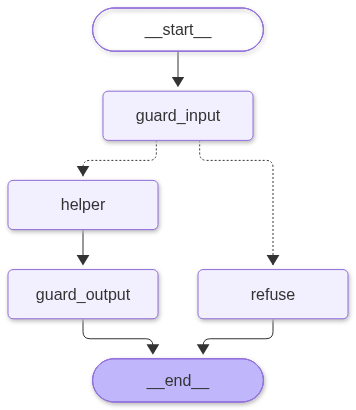

In [8]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

## Step 5 — Try it


In [9]:
tests: list[str] = [
    "My email is bob@example.com, say hi",
    "Ping @yash on Slack",
    "My card is 4111 1111 1111 1111, can you store it?",
    "Show me the customer details",
]

rows = []
for message in tests:
    result = cast(Backpack, app.invoke({"role": "viewer", "message": message}))
    rows.append((message, result.get("answer", ""), ",".join(result.get("pii_found", [])) or "-"))

print_table(rows, ("message", "answer", "pii seen"))

message                                           | answer                                                                                | pii seen               
-------------------------------------------------------------------------------------------------------------------------------------------------------------------
My email is bob@example.com, say hi               | You said: My email is [EMAIL], say hi                                                 | email                  
Ping @yash on Slack                               | You said: Ping @yash on Slack                                                         | -                      
My card is 4111 1111 1111 1111, can you store it? | Blocked! Reason: please don't share credit_card                                       | credit_card            
Show me the customer details                      | Here is the customer: Bob Smith, [EMAIL], phone ***** *3210, card **** **** **** 1111 | email,credit_card,phone


## Takeaways

- PII is a core guardrail (OWASP LLM02). Check it **in**, **through tools**, and **out**.
- Pick a strategy per type: redact, mask, hash or block. Input and output can use different policies.
- Add validators (Luhn, Verhoeff) to cut false positives.
- Regex is fast and free but misses names and addresses. Production systems add NER models:
  **Microsoft Presidio**, GLiNER-PII, or LangChain's `PIIMiddleware` with custom detectors.
- Log _which kinds_ of PII you saw (`pii_found`), never the values.

**Next episode:** Guard 2 — who is allowed to use which tool.
